In [1]:
# ==============================================================================
# COLAB CELL 1: MOUNT GOOGLE DRIVE & ENVIRONMENT SETUP
# ==============================================================================
from google.colab import drive
drive.mount('/content/drive')

import sys
import platform
import sklearn
import xgboost as xgb
import lightgbm as lgb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("="*60)
print("SYSTEM & ENVIRONMENT SPECIFICATIONS")
print("="*60)
print(f"Python Version      : {sys.version.split()[0]}")
print(f"Scikit-Learn Version: {sklearn.__version__}")
print(f"XGBoost Version     : {xgb.__version__}")
print(f"LightGBM Version    : {lgb.__version__}")

# Set plotting theme
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans']

Mounted at /content/drive
SYSTEM & ENVIRONMENT SPECIFICATIONS
Python Version      : 3.13.15
Scikit-Learn Version: 1.6.1
XGBoost Version     : 3.4.1
LightGBM Version    : 4.6.0


In [2]:
# ==============================================================================
# COLAB CELL 2: LOAD DATASET FROM GOOGLE DRIVE
# ==============================================================================
file_path = '/content/drive/MyDrive/TRIAL3/PFOA-ML.xlsx'

# Check available sheets
excel_file = pd.ExcelFile(file_path)
print(f"Available Excel Sheets: {excel_file.sheet_names}")

# Read the primary sheet
df = pd.read_excel(file_path, sheet_name=0)

print("\n" + "="*60)
print("DATASET OVERVIEW")
print("="*60)
print(f"Total Samples (N) : {df.shape[0]}")
print(f"Total Columns     : {df.shape[1]}")
print("\nFirst 5 Rows:")
display(df.head())

Available Excel Sheets: ['Sheet1']

DATASET OVERVIEW
Total Samples (N) : 72
Total Columns     : 11

First 5 Rows:


,ZTC STRUCTURE,Mass (g/mol),Density,HVF,APV,SSA,L,I.H,ATE,mmol/g,%wt
0,RHO,1417.3,632.7,0.930,1.470,2587.8,5.0,36.269,780.872,3.53,59.4
1,h8331018,3843.4,699.8,0.891,1.274,2172.8,12.0,36.626,1863.803,3.12,56.4
2,221_2_6,2690.4,754.2,0.937,1.242,2029.3,8.0,39.320,1234.474,2.97,55.2
3,SVR_2,2378.1,711.0,0.890,1.252,3337.8,7.0,39.047,1064.001,2.94,54.9
4,h8326849,2185.9,778.7,0.905,1.162,2051.7,6.0,39.485,918.558,2.74,53.2


In [3]:
# ==============================================================================
# COLAB CELL 3: FEATURE DEFINITION & TRAIN/TEST SPLIT
# ==============================================================================
from sklearn.model_selection import train_test_split

GLOBAL_SEED = 42

# Printing available columns in the dataframe to find correct matches
print("Available columns in the dataset:", list(df.columns))

FEATURE_COLUMNS = ['Mass (g/mol)', 'APV', 'HVF', 'Density', 'SSA']
TARGET_COLUMN = 'mmol/g'

# Fallback check to auto-detect if exact column names differ
if 'Mass (g/mol)' not in df.columns and 'Mass' in df.columns:
    FEATURE_COLUMNS[0] = 'Mass'

if 'mmol/g' not in df.columns and 'mmol_g' in df.columns:
    TARGET_COLUMN = 'mmol_g'

# Verify columns exist in dataframe
missing_cols = [col for col in FEATURE_COLUMNS + [TARGET_COLUMN] if col not in df.columns]
if missing_cols:
    raise ValueError(f"The following required columns are missing from the dataset: {missing_cols}")

X = df[FEATURE_COLUMNS]
y = df[TARGET_COLUMN]

# 90% Training, 10% Holdout Test Partition (Seed locked for reproducibility)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.10, random_state=GLOBAL_SEED
)

print(f"\nPredictor Features      : {FEATURE_COLUMNS}")
print(f"Training Set Samples    : {X_train.shape[0]}")
print(f"Holdout Test Samples    : {X_test.shape[0]}")
print(f"\nTarget Variable Statistics ({TARGET_COLUMN}):")
print(f"• Mean ± SD : {y.mean():.4f} ± {y.std():.4f} mmol/g")
print(f"• Range     : [{y.min():.4f}, {y.max():.4f}] mmol/g")

Available columns in the dataset: ['ZTC STRUCTURE', 'Mass (g/mol)', 'Density', 'HVF', 'APV', 'SSA', 'L', 'I.H', 'ATE', 'mmol/g', '%wt']

Predictor Features      : ['Mass (g/mol)', 'APV', 'HVF', 'Density', 'SSA']
Training Set Samples    : 64
Holdout Test Samples    : 8

Target Variable Statistics (mmol/g):
• Mean ± SD : 1.3592 ± 0.9775 mmol/g
• Range     : [0.0000, 3.5300] mmol/g


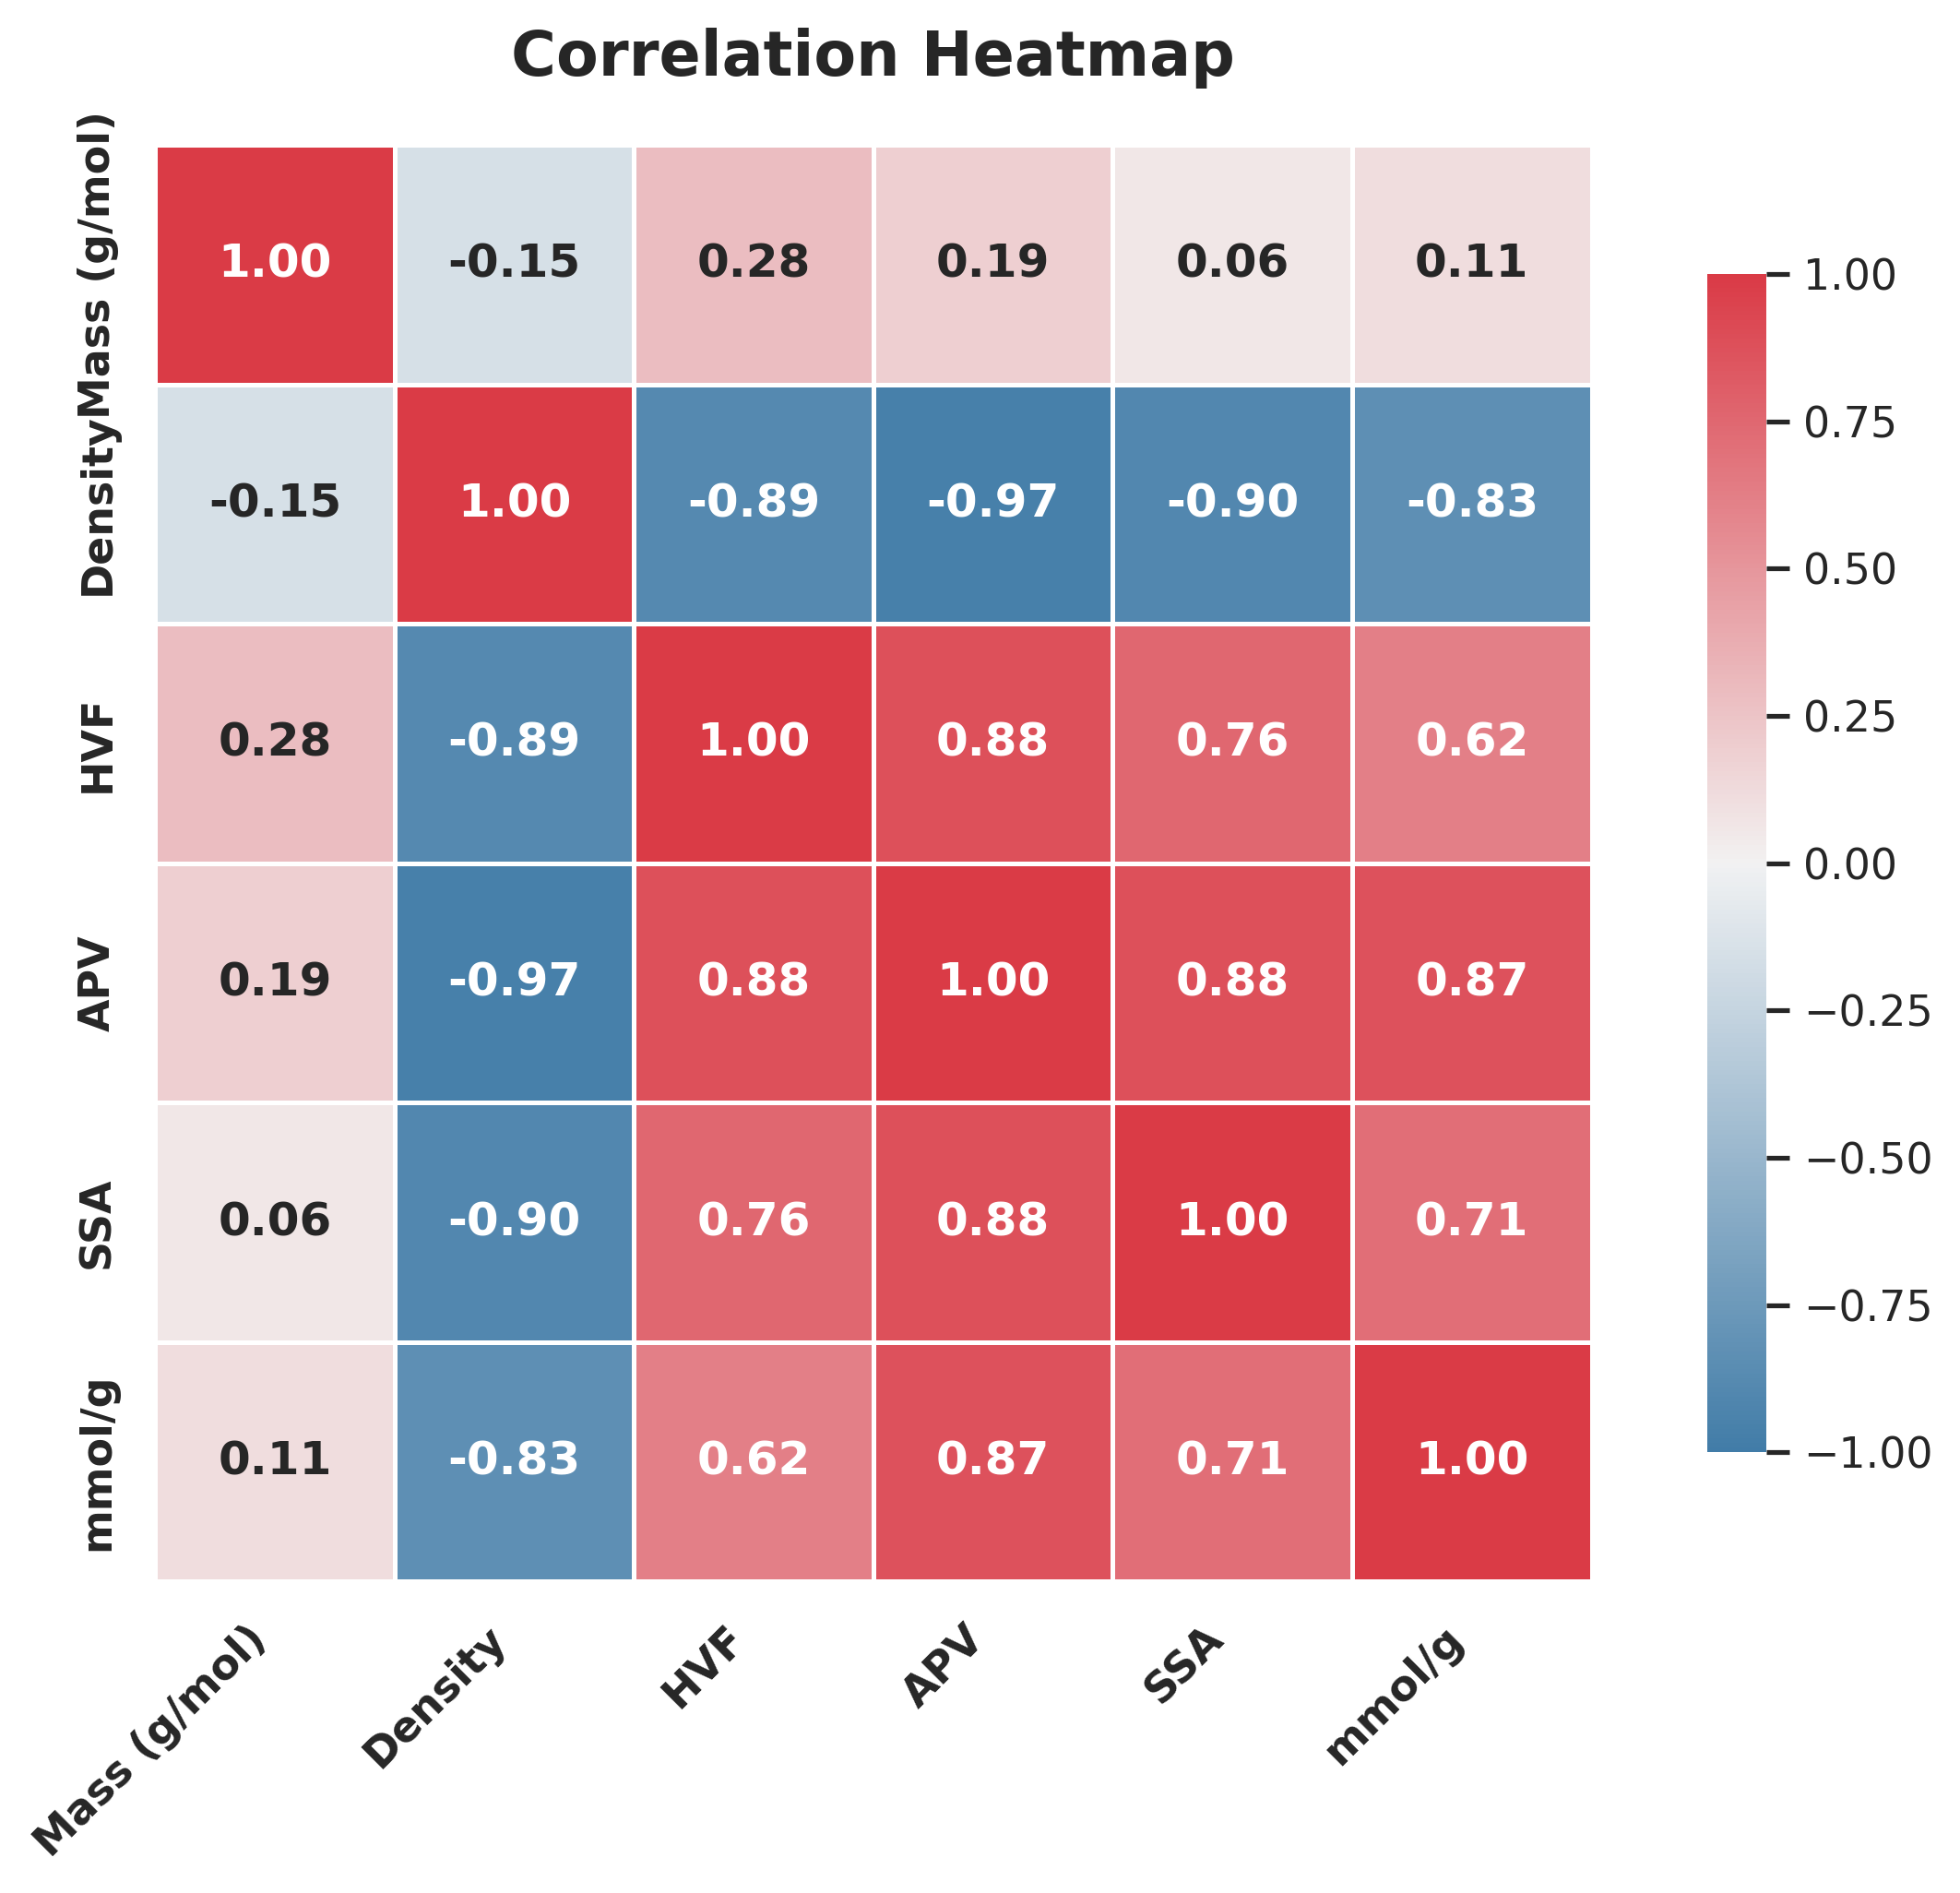

In [4]:
# ==============================================================================
# COLAB CELL 4: HIGH-RESOLUTION PEARSON CORRELATION HEATMAP
# ==============================================================================
plt.figure(figsize=(9, 7), dpi=300)

ordered_cols = ['Mass (g/mol)', 'Density', 'HVF', 'APV', 'SSA', TARGET_COLUMN]
corr_df = X_train.copy()
corr_df[TARGET_COLUMN] = y_train

existing_cols = [col for col in ordered_cols if col in corr_df.columns]
corr_matrix = corr_df[existing_cols].corr()

cmap = sns.diverging_palette(240, 10, as_cmap=True)

ax = sns.heatmap(corr_matrix, cmap=cmap, vmax=1.0, vmin=-1.0, center=0,
                 square=True, linewidths=1.2, cbar_kws={"shrink": .82},
                 annot=True, fmt=".2f", annot_kws={"size": 12, "weight": "bold"})

plt.title("Correlation Heatmap", fontsize=16, fontweight='bold', pad=18)
plt.xticks(rotation=45, ha='right', fontsize=11, fontweight='bold')
plt.yticks(fontsize=11, fontweight='bold')
cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=11)
plt.tight_layout()
plt.show()

In [5]:
# ==============================================================================
# COLAB CELL 5: COMPREHENSIVE REGRESSION PIPELINE, TUNING, MAE & MSE EVALUATION
# ==============================================================================
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# --- 1. HANDLE TARGET NA's ---
train_non_nan_mask = ~y_train.isna()
test_non_nan_mask = ~y_test.isna()

X_train_clean = X_train[train_non_nan_mask]
y_train_clean = y_train[train_non_nan_mask]
X_test_clean = X_test[test_non_nan_mask]
y_test_clean = y_test[test_non_nan_mask]

# --- 2. DEFINE PIPELINE WITH IMPUTER, SCALER & MULTIPLE MODELS ---
cv_strategy = KFold(n_splits=5, shuffle=True, random_state=GLOBAL_SEED)

regressors = {
    'Linear Regression': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('model', LinearRegression())
    ]),
    'Ridge Regression': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('model', Ridge(random_state=GLOBAL_SEED))
    ]),
    'Lasso Regression': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('model', Lasso(random_state=GLOBAL_SEED, max_iter=10000))
    ]),
    'Support Vector Regressor (SVR)': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('model', SVR())
    ]),
    'Random Forest': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('model', RandomForestRegressor(random_state=GLOBAL_SEED))
    ]),
    'Gradient Boosting': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('model', GradientBoostingRegressor(random_state=GLOBAL_SEED))
    ])
}

param_grids = {
    'Linear Regression': {},
    'Ridge Regression': {
        'model__alpha': [0.1, 1.0, 10.0, 100.0]
    },
    'Lasso Regression': {
        'model__alpha': [0.001, 0.01, 0.1, 1.0, 10.0]
    },
    'Support Vector Regressor (SVR)': {
        'model__C': [0.1, 1.0, 10.0, 100.0],
        'model__epsilon': [0.01, 0.1, 0.2],
        'model__kernel': ['rbf', 'linear']
    },
    'Random Forest': {
        'model__n_estimators': [50, 100, 200],
        'model__max_depth': [5, 10, None],
        'model__min_samples_split': [2, 5]
    },
    'Gradient Boosting': {
        'model__n_estimators': [50, 100],
        'model__learning_rate': [0.01, 0.1],
        'model__max_depth': [3, 5]
    }
}

evaluation_results = []
trained_models = {}

print(f"Initial training samples: {len(X_train)} | Cleaned training samples: {len(X_train_clean)}")
print("Executing 5-Fold CV Hyperparameter Tuning & Evaluation across all models...\n")

for name, pipeline in regressors.items():
    grid = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[name],
        cv=cv_strategy,
        scoring='neg_mean_squared_error',
        n_jobs=-1
    )
    grid.fit(X_train_clean, y_train_clean)
    best_model = grid.best_estimator_
    trained_models[name] = best_model

    y_pred = best_model.predict(X_test_clean)

    mae = mean_absolute_error(y_test_clean, y_pred)
    mse = mean_squared_error(y_test_clean, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test_clean, y_pred)

    evaluation_results.append({
        'Model Architecture': name,
        'MAE (mmol/g)': f"{mae:.4f}",
        'MSE ((mmol/g)^2)': f"{mse:.4f}",
        'RMSE (mmol/g)': f"{rmse:.4f}",
        'R² Score': f"{r2:.4f}",
        'Best Hyperparameters': str(grid.best_params_)
    })

results_df = pd.DataFrame(evaluation_results)
print("="*95)
print("HOLDOUT TEST SET PERFORMANCE MATRIX (MAE & MSE)")
print("="*95)
print(results_df.to_string(index=False))

Initial training samples: 64 | Cleaned training samples: 60
Executing 5-Fold CV Hyperparameter Tuning & Evaluation across all models...

HOLDOUT TEST SET PERFORMANCE MATRIX (MAE & MSE)
            Model Architecture MAE (mmol/g) MSE ((mmol/g)^2) RMSE (mmol/g) R² Score                                                                Best Hyperparameters
             Linear Regression       0.3345           0.1472        0.3837   0.8593                                                                                  {}
              Ridge Regression       0.2920           0.0942        0.3069   0.9100                                                               {'model__alpha': 1.0}
              Lasso Regression       0.2926           0.1042        0.3228   0.9004                                                              {'model__alpha': 0.01}
Support Vector Regressor (SVR)       0.2980           0.0976        0.3124   0.9067                 {'model__C': 1.0, 'model__epsilon': 0.1, 'm

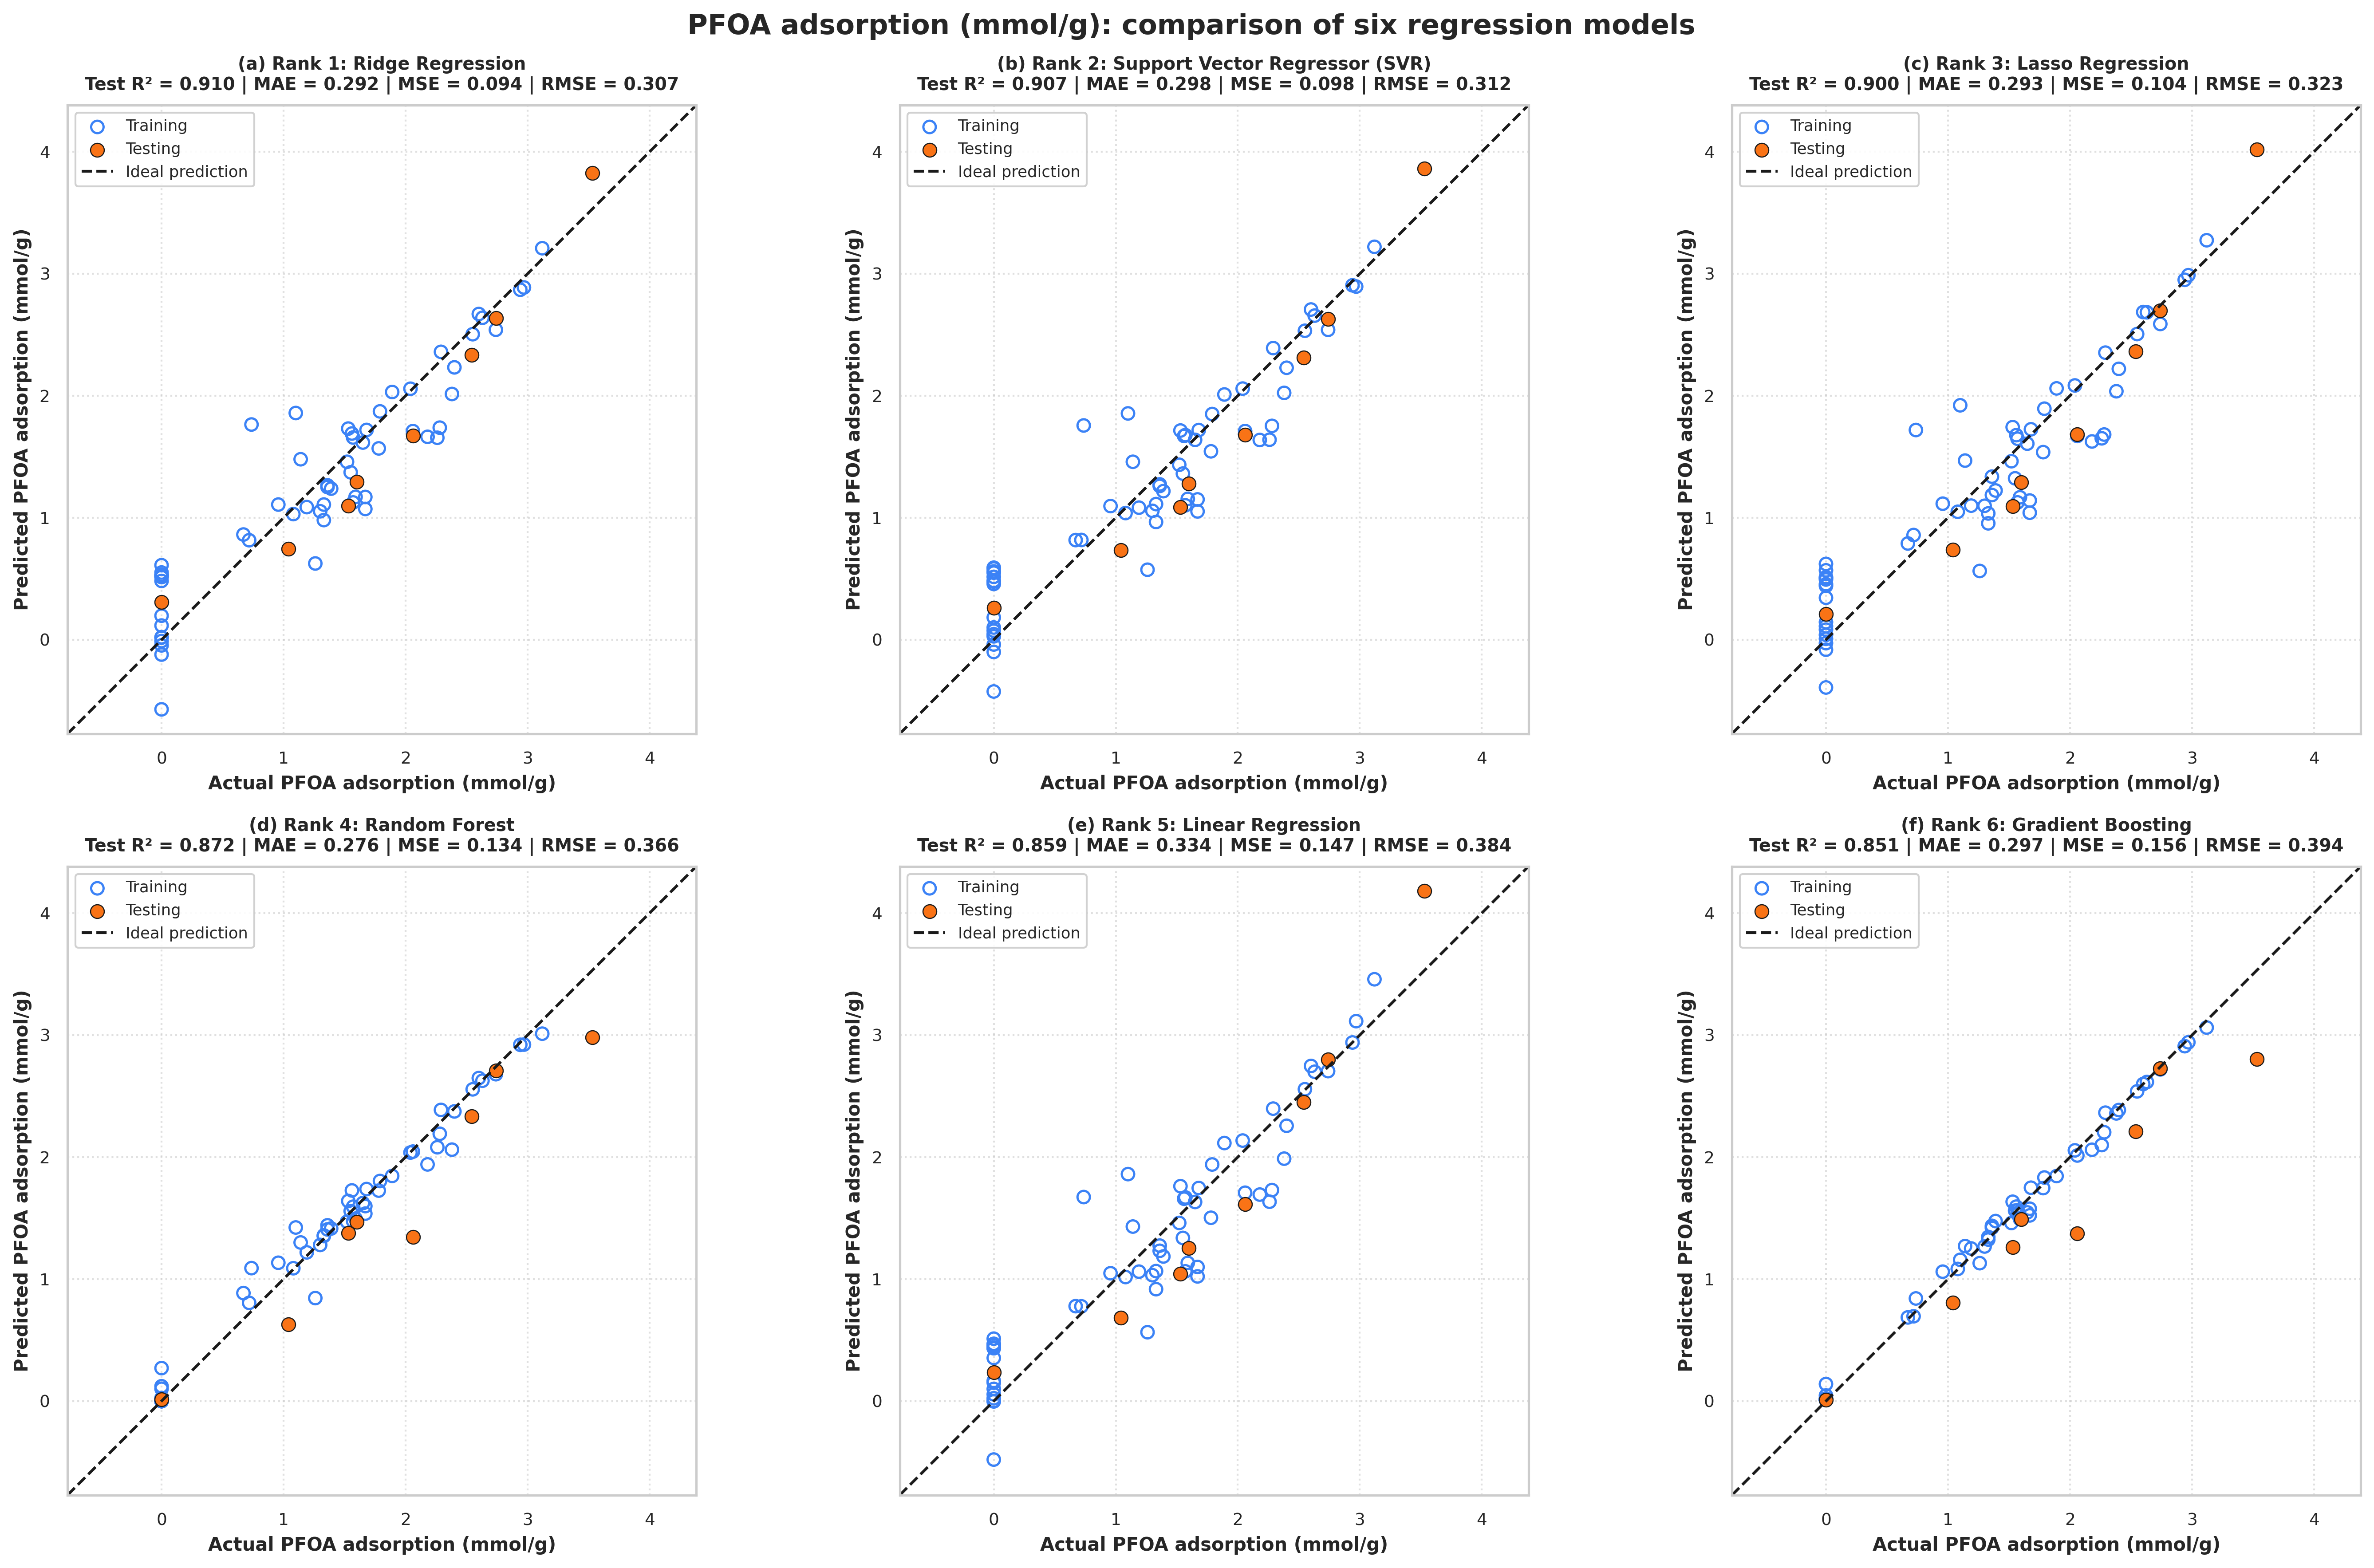

In [6]:
# ==============================================================================
# COLAB CELL 6: RANKED HIGH-RESOLUTION PARITY PLOTS (SORTED BY TEST R² DESCENDING)
# ==============================================================================
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# 1. Collect model performances and sort by Test R² descending
model_performances = []

for name, model in trained_models.items():
    y_train_pred = model.predict(X_train_clean)
    y_test_pred = model.predict(X_test_clean)

    train_r2 = r2_score(y_train_clean, y_train_pred)
    test_r2 = r2_score(y_test_clean, y_test_pred)
    test_mae = mean_absolute_error(y_test_clean, y_test_pred)
    test_mse = mean_squared_error(y_test_clean, y_test_pred)
    test_rmse = np.sqrt(test_mse)

    model_performances.append({
        'name': name,
        'model': model,
        'train_r2': train_r2,
        'test_r2': test_r2,
        'test_mae': test_mae,
        'test_mse': test_mse,
        'test_rmse': test_rmse,
        'y_train_pred': y_train_pred,
        'y_test_pred': y_test_pred
    })

# Sort models by Test R² in descending order (Rank 1 = highest Test R²)
model_performances = sorted(model_performances, key=lambda x: x['test_r2'], reverse=True)

# 2. Set up a 2x3 subplot grid for the 6 models
fig, axes = plt.subplots(2, 3, figsize=(19, 12), dpi=300)
axes = axes.flatten()

# Global min and max for consistent axis scaling across all subplots
all_actuals = pd.concat([y_train_clean, y_test_clean])
all_preds = np.concatenate([m['y_train_pred'] for m in model_performances] + [m['y_test_pred'] for m in model_performances])
min_val = min(all_actuals.min(), all_preds.min()) - 0.2
max_val = max(all_actuals.max(), all_preds.max()) + 0.2

alphabet_labels = ['a', 'b', 'c', 'd', 'e', 'f']

for idx, item in enumerate(model_performances):
    ax = axes[idx]
    rank = idx + 1
    name = item['name']
    test_r2 = item['test_r2']
    test_mae = item['test_mae']
    test_mse = item['test_mse']
    test_rmse = item['test_rmse']

    y_train_pred = item['y_train_pred']
    y_test_pred = item['y_test_pred']

    # Scatter plots matching reference style: Training (open blue circles), Testing (filled orange circles)
    ax.scatter(y_train_clean, y_train_pred, facecolors='none', edgecolors='#3B82F6', linewidths=1.2, s=45, label='Training')
    ax.scatter(y_test_clean, y_test_pred, color='#F97316', edgecolors='k', linewidths=0.6, s=55, marker='o', label='Testing')

    # Ideal prediction line (y = x)
    ax.plot([min_val, max_val], [min_val, max_val], 'k--', lw=1.5, label='Ideal prediction')

    # Subplot titles including R², MAE, MSE, and RMSE immediately after
    title_str = f"({alphabet_labels[idx]}) Rank {rank}: {name}\nTest R² = {test_r2:.3f} | MAE = {test_mae:.3f} | MSE = {test_mse:.3f} | RMSE = {test_rmse:.3f}"
    ax.set_title(title_str, fontsize=9.5, fontweight='bold', pad=8)
    ax.set_xlabel(f"Actual PFOA adsorption ({TARGET_COLUMN})", fontsize=10, fontweight='bold')
    ax.set_ylabel(f"Predicted PFOA adsorption ({TARGET_COLUMN})", fontsize=10, fontweight='bold')

    ax.set_xlim(min_val, max_val)
    ax.set_ylim(min_val, max_val)
    ax.set_aspect('equal', adjustable='box')

    ax.tick_params(axis='both', which='major', labelsize=9)
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.legend(loc='upper left', fontsize=8.5, framealpha=0.9)

# Clean up layout
plt.suptitle(f"PFOA adsorption ({TARGET_COLUMN}): comparison of six regression models", fontsize=15, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

RANDOM FOREST FEATURE IMPORTANCE RANKING (%)
     Feature Importance (%)
     Density         79.02%
         APV         12.42%
         HVF          4.10%
         SSA          3.24%
Mass (g/mol)          1.22%


/tmp/ipykernel_785/1763581555.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x='Importance (%)', y='Feature', data=feature_importance_df, palette='Blues_r')


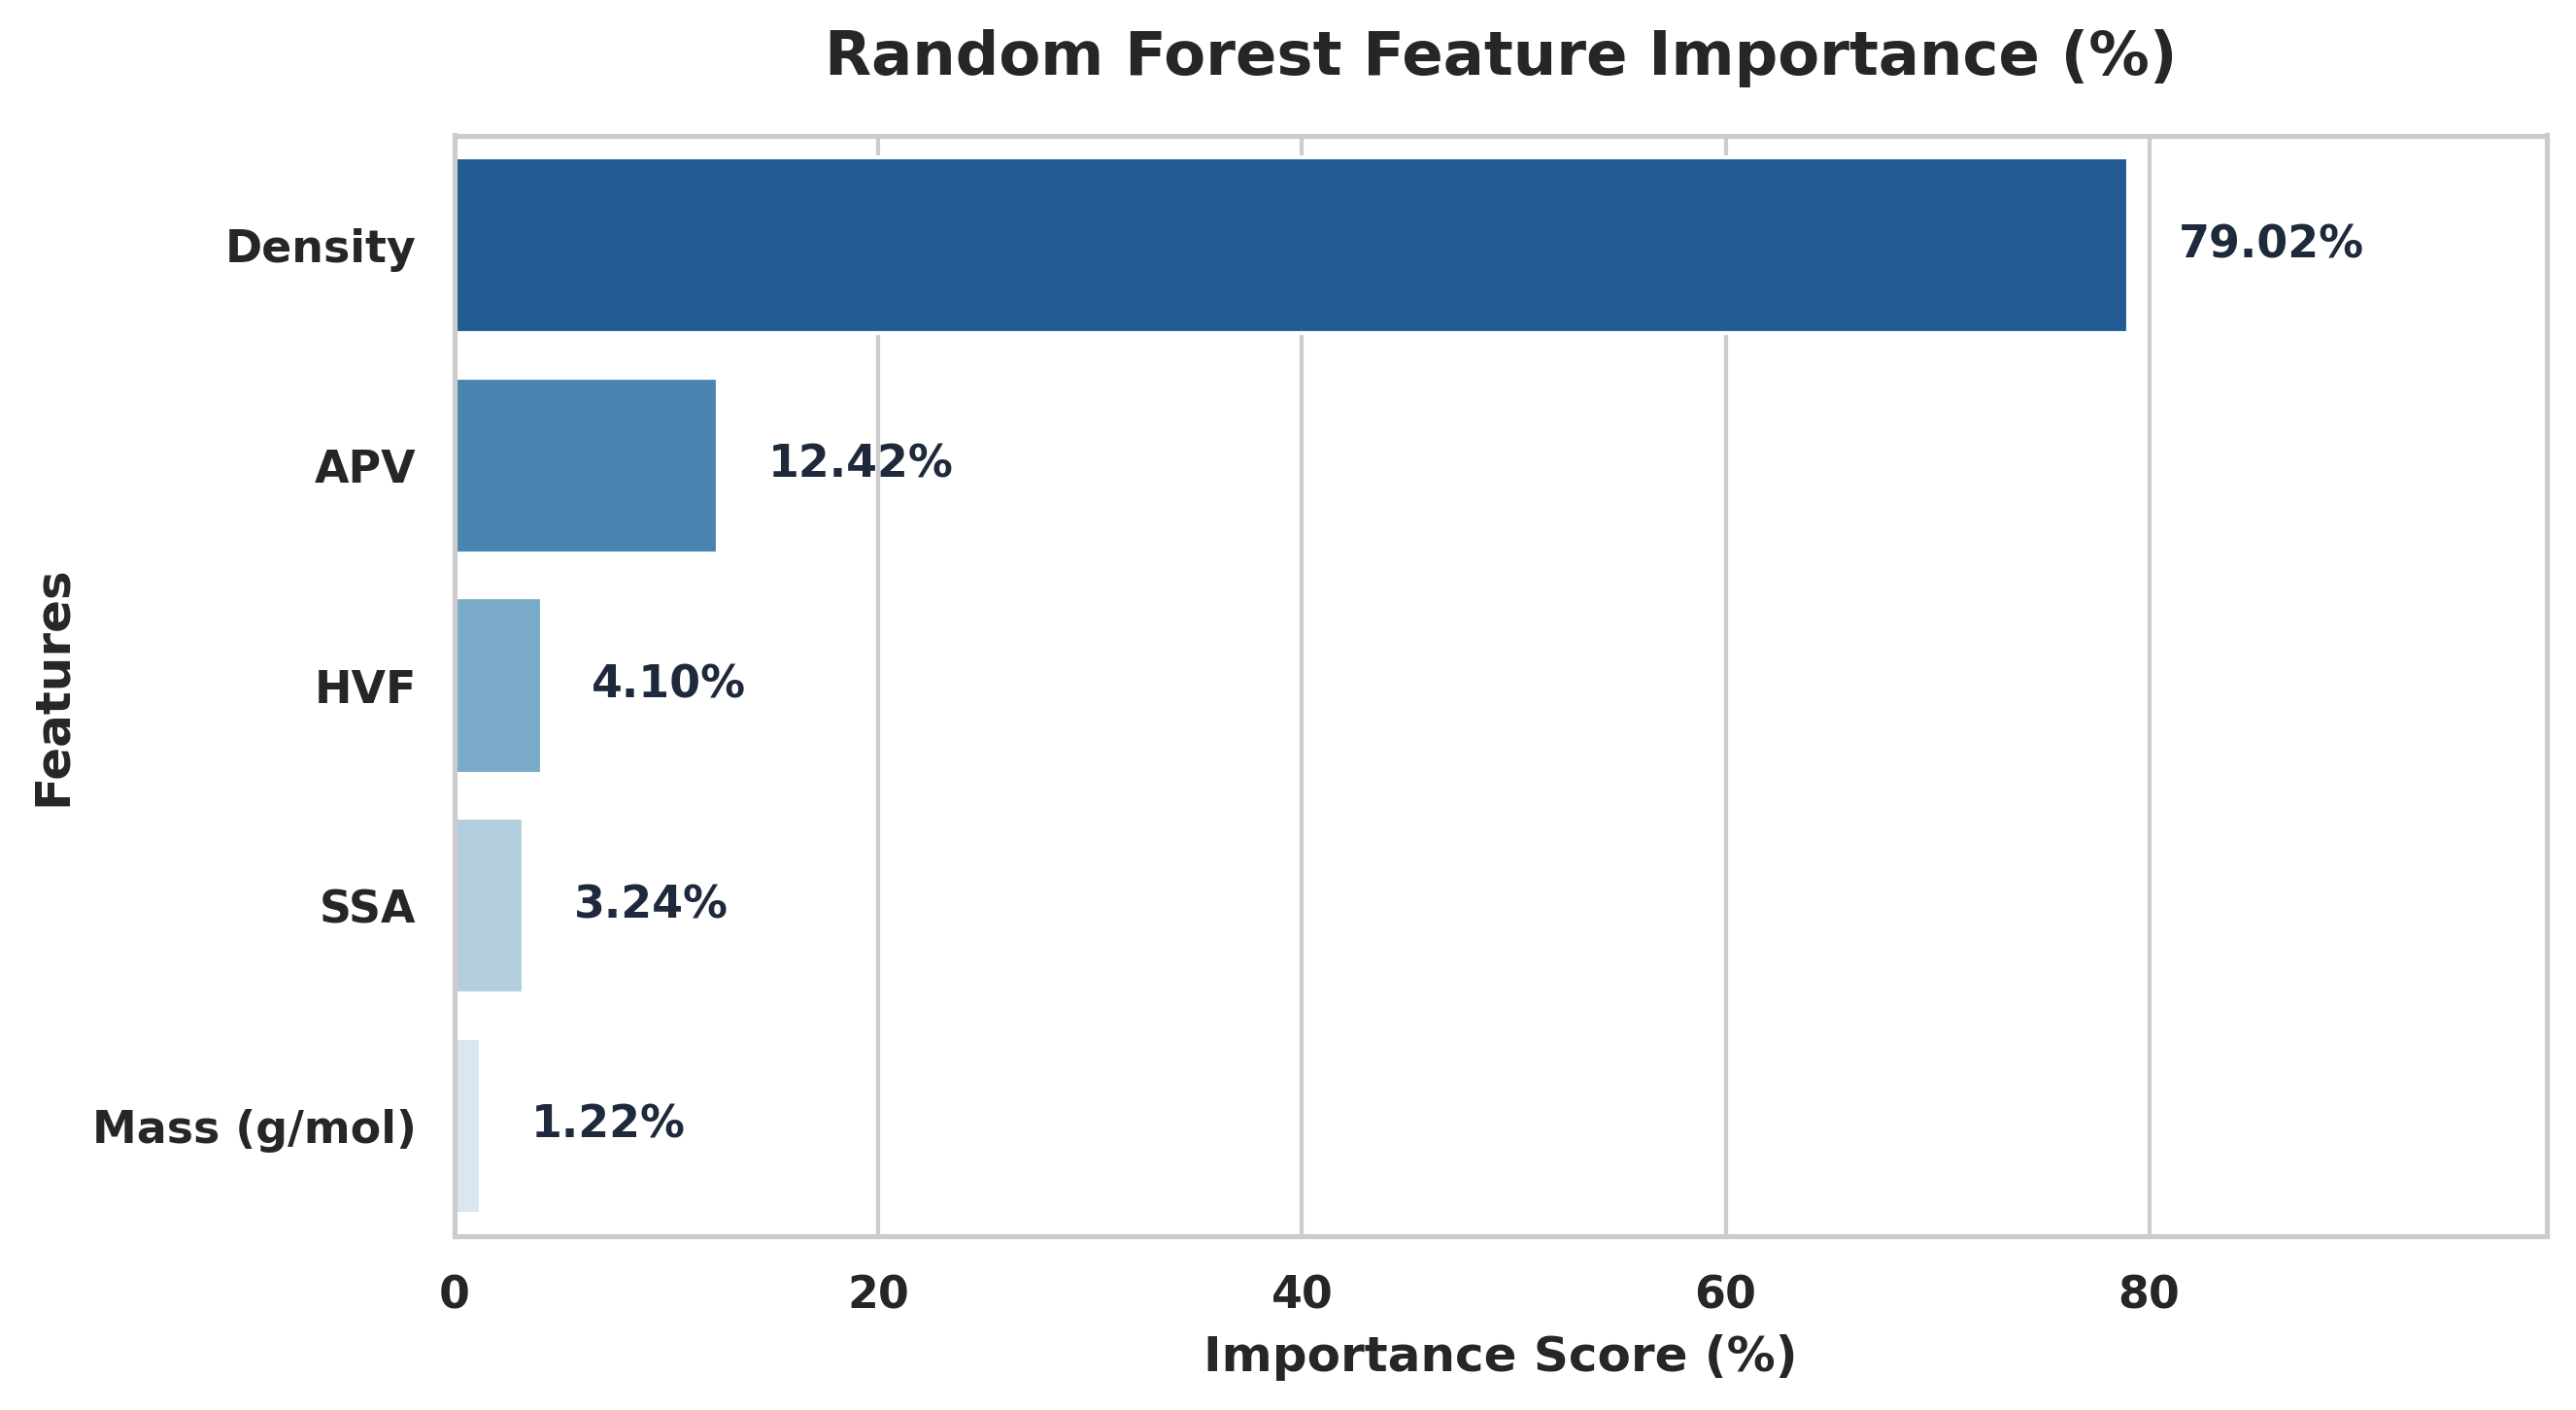

In [7]:
# ==============================================================================
# COLAB CELL 7: HIGH-RESOLUTION RANDOM FOREST FEATURE IMPORTANCE RANKING (%)
# ==============================================================================
rf_pipeline = trained_models['Random Forest']
rf_model = rf_pipeline.named_steps['model']
importances = rf_model.feature_importances_

importance_percentages = (importances / importances.sum()) * 100

feature_importance_df = pd.DataFrame({
    'Feature': FEATURE_COLUMNS,
    'Importance (%)': importance_percentages
}).sort_values(by='Importance (%)', ascending=False)

print("="*65)
print("RANDOM FOREST FEATURE IMPORTANCE RANKING (%)")
print("="*65)
display_importance_df = feature_importance_df.copy()
display_importance_df['Importance (%)'] = display_importance_df['Importance (%)'].apply(lambda x: f"{x:.2f}%")
print(display_importance_df.to_string(index=False))

plt.figure(figsize=(9, 5), dpi=300)
max_imp = feature_importance_df['Importance (%)'].max()

# Plot horizontal bar chart
ax = sns.barplot(x='Importance (%)', y='Feature', data=feature_importance_df, palette='Blues_r')
plt.title("Random Forest Feature Importance (%)", fontsize=15, fontweight='bold', pad=15)
plt.xlabel("Importance Score (%)", fontsize=12, fontweight='bold')
plt.ylabel("Features", fontsize=12, fontweight='bold')
plt.xticks(fontsize=11, fontweight='bold')
plt.yticks(fontsize=11, fontweight='bold')

# Place value labels OUTSIDE the bars in empty whitespace to the right
for p in ax.patches:
    width = p.get_width()
    if width > 0:
        ax.annotate(f"{width:.2f}%",
                    (width + (max_imp * 0.03), p.get_y() + p.get_height() / 2.),
                    ha='left', va='center',
                    fontsize=11, fontweight='bold', color='#1E293B')

# Expand X-axis limit to comfortably fit the outside annotations
plt.xlim(0, max_imp * 1.25)
plt.tight_layout()
plt.show()